# Task 2 marginals EDA: would parametric marginals beat the smoothed histograms?

naive Bayes ของงาน 2 (`pis/task2_naive_bayes.py`) ประมาณความหนาแน่นของแต่ละ feature ต่อคลาสด้วย histogram 200 ช่องที่ปรับเรียบด้วย sigma 5 ถ้าข้อมูลจำลองสุ่มแต่ละ feature จาก distribution มาตรฐาน (normal, lognormal, gamma, ...) การใช้ distribution นั้นตรงๆ อาจได้ density ที่แม่นกว่า

- **B1:** ทุก feature ต่อเนื่อง × คลาส เทียบ held-out log-likelihood ของ 6 family กับ histogram ที่ NB ใช้
- **B2 (oracle):** NB ที่ใช้ family ที่ดีที่สุดของแต่ละ feature/คลาส (เลือกแบบ held-out ภายใน fold train) ทั้งเดี่ยวและใน blend 0.6/0.4 กับ CatBoost

Metric: macro F1 fold: StratifiedKFold 3, seed 342 OOF ปัจจุบัน: `outputs/experiments/task2_oof.csv` (`experiments/task2/eda/make_oof.py`, 12 threads) ไม่อ่านแถว test

**กฎตัดสิน:** ทำ experiment เฉพาะถ้าได้ ≥ +0.0015 macro F1 และชนะครบ 3 fold

## Imports

In [1]:
import os, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from catboost import CatBoostClassifier
from scipy import stats
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold

pd.set_option('display.width', 200)  # keep wide tables on one line instead of "..."
warnings.filterwarnings('ignore', category=RuntimeWarning)  # scipy fits on boundary cases

## Setup

In [2]:
# Find the repo root (the folder with `run.py`), move there and add it to `sys.path`, so paths like `outputs/...` and `import pis` work wherever the kernel started.
ROOT = Path.cwd().resolve()
while not (ROOT / 'run.py').exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('run.py not found; open this notebook inside the repo')
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from pis.common import DEFAULT_DATA
from pis.tabular import TASK2_BAYES_WEIGHT, _prepare
from pis.task2_naive_bayes import SmoothNaiveBayes, geometric_blend

BLUE, RED, ORANGE, INK, GRID = '#2a78d6', '#e34948', '#eb6834', '#52514e', '#e5e4df'
MIN_GAIN = 0.0015
NAMES = ['Casual', 'Grinder', 'Social', 'Whale']


def tidy(ax, grid='x'):
    ax.grid(axis=grid, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)


def macro_f1(y, proba):
    return f1_score(y, proba.argmax(axis=1), average='macro')


print(f"repo root: {ROOT}")

repo root: C:\Users\acer\Desktop\cpe342\project\player-intelligence-system-cpe342


## Load data & split the current blend

NB ของแต่ละ fold เทรนใหม่ (deterministic) CatBoost โหลดจาก fold model ที่ `make_oof.py` บันทึกไว้ แล้วเช็คว่าผสมกลับได้ OOF เดิม (macro F1 0.7567)

In [3]:
train = pd.read_csv(DEFAULT_DATA / '02_multiclass_classification' / 'train.csv')
y = train['segment'].astype(int).to_numpy()
oof = pd.read_csv('outputs/experiments/task2_oof.csv')
assert (oof['player_id'].to_numpy() == train['player_id'].to_numpy()).all()
P = oof[sorted(c for c in oof.columns if c.startswith('probability_'))].to_numpy()
assert abs(macro_f1(y, P) - 0.7567) < 5e-4

x, _, _ = _prepare(train, train.drop(columns='segment'), 'segment')
bayes_cols = [c for c in x.columns if not c.startswith('random_metric')]
bx = train[bayes_cols]
folds = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=342).split(x, y))
P_nb, P_cb, nbs = np.zeros_like(P), np.zeros_like(P), []
for i, (a, b) in enumerate(folds, 1):
    nb = SmoothNaiveBayes().fit(bx.iloc[a], y[a])
    P_nb[b] = nb.predict_proba(bx.iloc[b])
    P_cb[b] = CatBoostClassifier().load_model(f'outputs/experiments/task2_missing_eda_run/task2_fold{i}.cbm').predict_proba(x.iloc[b])
    nbs.append(nb)
assert np.allclose(geometric_blend(P_cb, P_nb, TASK2_BAYES_WEIGHT), P, atol=1e-6)
continuous = list(nbs[0].continuous_)
print(f"rows {len(y):,} | NB features {len(bayes_cols)}: {len(continuous)} continuous (histogram), {len(nbs[0].discrete_)} discrete (frequency table)")
print(f"macro F1: NB {macro_f1(y, P_nb):.4f} | CatBoost {macro_f1(y, P_cb):.4f} | blend {macro_f1(y, P):.4f}")

rows 104,000 | NB features 41: 26 continuous (histogram), 15 discrete (frequency table)
macro F1: NB 0.7564 | CatBoost 0.7516 | blend 0.7567


## B1. Parametric families vs the smoothed histogram

แต่ละ fold: fit บนแถวของคลาสนั้นใน 2 fold train แล้วคิด log-likelihood เฉลี่ยต่อแถวบน fold ที่เหลือ (เฉพาะแถวที่มีค่า) แล้วเฉลี่ย 3 fold

- family: normal, lognormal (loc 0, ค่า > 0), gamma (loc 0, ค่า > 0), uniform (min ถึง max), exponential (loc 0, ค่า ≥ 0), beta (ค่าอยู่ใน [0, 1])
- histogram: ความน่าจะเป็นของช่อง / ความกว้างช่อง จาก NB ที่เทรนบน fold เดียวกัน (ค่านอก 0.1% ถึง 99.9% ถูก clip เข้าช่องริมแบบที่ NB ทำ)
- family ที่ใช้ไม่ได้กับข้อมูล (ค่าติดลบ / เกิน 1) หรือให้ log-likelihood เป็น −∞ บนแถวที่วัด (เช่น uniform เจอค่านอกช่วง) ถือว่า invalid

In [4]:
FAMILIES = ['normal', 'lognormal', 'gamma', 'uniform', 'exponential', 'beta']


def fit_family(family, v):
    # Frozen scipy distribution fitted to v, or None when the family does not apply.
    if family == 'normal':
        return stats.norm(*stats.norm.fit(v))
    if family == 'lognormal' and v.min() > 0:
        s, loc, scale = stats.lognorm.fit(v, floc=0); return stats.lognorm(s, loc, scale)
    if family == 'gamma' and v.min() > 0:
        a, loc, scale = stats.gamma.fit(v, floc=0); return stats.gamma(a, loc, scale)
    if family == 'uniform':
        return stats.uniform(v.min(), v.max() - v.min())
    if family == 'exponential' and v.min() >= 0:
        return stats.expon(0, v.mean())
    if family == 'beta' and v.min() >= 0 and v.max() <= 1:
        a, b_, loc, scale = stats.beta.fit(np.clip(v, 1e-6, 1 - 1e-6), floc=0, fscale=1); return stats.beta(a, b_, loc, scale)
    return None


def hist_logdensity(nb, column, ci, v):
    edges, table = nb.continuous_[column]
    idx = np.clip(np.searchsorted(edges, v, side='right') - 1, 0, table.shape[1] - 1)
    return table[ci, idx] - np.log(edges[1] - edges[0])


def heldout(fit_rows, eval_rows):
    # Mean held-out log-likelihood per (feature, class, family); the histogram comes from an NB fitted on fit_rows.
    nb = SmoothNaiveBayes().fit(bx.iloc[fit_rows], y[fit_rows])
    out = {}
    for column in continuous:
        v_all = bx[column].to_numpy(dtype=float)
        for ci, k in enumerate(nb.classes_):
            va = v_all[fit_rows][(y[fit_rows] == k) & ~np.isnan(v_all[fit_rows])]
            vb = v_all[eval_rows][(y[eval_rows] == k) & ~np.isnan(v_all[eval_rows])]
            out[(column, k, 'histogram (current)')] = hist_logdensity(nb, column, ci, vb).mean()
            for family in FAMILIES:
                dist = fit_family(family, va)
                ll = dist.logpdf(vb) if dist is not None else np.array([-np.inf])
                out[(column, k, family)] = ll.mean() if np.isfinite(ll).all() else np.nan
    return pd.Series(out)


b1 = pd.concat([heldout(a, b) for a, b in folds], axis=1).mean(axis=1).unstack()   # rows (feature, class), columns family
b1 = b1[['histogram (current)'] + FAMILIES]
best_family = b1[FAMILIES].idxmax(axis=1)
b1_summary = pd.DataFrame({'best family': best_family, 'best family log-lik': b1[FAMILIES].max(axis=1),
                           'histogram log-lik': b1['histogram (current)']})
b1_summary['gain vs histogram'] = b1_summary['best family log-lik'] - b1_summary['histogram log-lik']
b1_summary.index = b1_summary.index.set_names(['feature', 'class'])
b1_summary = b1_summary.rename(index=dict(enumerate(NAMES)), level='class')
print(f"{len(b1_summary)} feature/class pairs | a parametric family beats the histogram in {(b1_summary['gain vs histogram'] > 0).sum()} | "
      f"median gain {b1_summary['gain vs histogram'].median():+.4f} nats per row")
display(pd.crosstab(b1_summary['best family'], b1_summary['gain vs histogram'] > 0).rename(columns={True: 'beats histogram', False: 'loses to histogram'}))
b1_summary.sort_values('gain vs histogram', ascending=False).style.format({'best family log-lik': '{:.4f}', 'histogram log-lik': '{:.4f}', 'gain vs histogram': '{:+.4f}'}) \
    .bar(subset='gain vs histogram', align=0, color=[RED, BLUE]).set_caption('B1: best family per feature and class, held-out log-likelihood per row (mean of 3 folds)')

104 feature/class pairs | a parametric family beats the histogram in 0 | median gain -0.0556 nats per row


gain vs histogram,loses to histogram
best family,
beta,12
exponential,7
gamma,22
normal,59
uniform,4


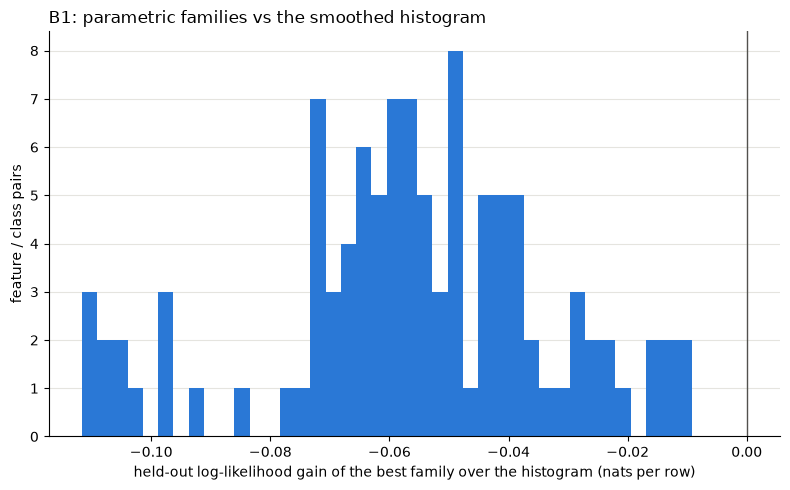

In [5]:
g = b1_summary['gain vs histogram'].sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(g, bins=40, color=BLUE)
ax.axvline(0, color=INK, linewidth=1)
ax.set_xlabel('held-out log-likelihood gain of the best family over the histogram (nats per row)')
ax.set_ylabel('feature / class pairs')
ax.set_title('B1: parametric families vs the smoothed histogram', loc='left')
tidy(ax, 'y')
plt.tight_layout()
plt.show()

**NOTE:**


**The smoothed histogram wins every one of the 104 feature/class pairs.** The best parametric family is still worse by 0.009 to 0.112 nats per row (median 0.056). Normal is the best family for 59 pairs and gamma for 22. Beta (the `item_type_preference_*` shares), exponential (counts such as `login_streak` and `tournament_entries` for Casual) and uniform (`ranked_participation_rate`) win the rest, but none of them beats the histogram.

The closest calls are features that look close to normal (`days_since_last_login`, `avg_match_length`, `win_rate_ranked`), where the histogram is better by about 0.01. So the generator did not draw these features from textbook families, or it clipped or mixed them, and the 200-bin histogram with sigma 5 already follows the shapes better than any single family.

## B2. Oracle: NB with the best family per feature and class

ทำแบบ honest: ในแต่ละ fold ด้านนอก เลือก family (รวม histogram เดิม) ของแต่ละ feature/คลาสจาก held-out log-likelihood ด้วยการแบ่ง 2 ส่วนภายใน fold train (StratifiedKFold 2, seed 342) แล้ว fit family ที่เลือกบน fold train ทั้งหมด และคิดคะแนนบน fold ด้านนอก

NB แบบใหม่เหมือน NB เดิมทุกอย่าง (feature ไม่ต่อเนื่อง, ตารางความถี่, ข้ามค่าว่าง, prior) ต่างแค่ density ของ feature/คลาสที่ family ชนะ log density ของ family ถูกตัดล่างที่ density ต่ำสุดของ histogram ของ feature นั้น (เหมือน floor 1e-3 ของ NB) เทียบทั้งเดี่ยวและใน blend 0.6/0.4 กับ CatBoost

In [6]:
def family_nb_proba(fit_rows, eval_rows, choice):
    # NB fitted on fit_rows with per (feature, class) family choice; probabilities for eval_rows.
    nb = SmoothNaiveBayes().fit(bx.iloc[fit_rows], y[fit_rows])
    ll = nb.feature_log_likelihoods(bx.iloc[eval_rows])                 # (rows, features, classes)
    names = nb.feature_names_
    for column in continuous:
        j = names.index(column)
        edges, table = nb.continuous_[column]
        width = edges[1] - edges[0]
        v_eval = bx[column].to_numpy(dtype=float)[eval_rows]
        known = ~np.isnan(v_eval)
        ll[known, j] -= np.log(width)                                    # histogram in density units, as the families
        floor = table.min() - np.log(width)
        v_fit = bx[column].to_numpy(dtype=float)[fit_rows]
        for ci, k in enumerate(nb.classes_):
            family = choice.get((column, k), 'histogram (current)')
            if family == 'histogram (current)':
                continue
            dist = fit_family(family, v_fit[(y[fit_rows] == k) & ~np.isnan(v_fit)])
            ll[known, j, ci] = np.maximum(dist.logpdf(v_eval[known]), floor)
    scores = nb.log_prior_ + ll.sum(axis=1)
    scores -= scores.max(axis=1, keepdims=True)
    p = np.exp(scores)
    return p / p.sum(axis=1, keepdims=True)


P_fam, chosen = np.zeros_like(P), []
for a, b in folds:
    inner = list(StratifiedKFold(n_splits=2, shuffle=True, random_state=342).split(a, y[a]))
    ll_inner = pd.concat([heldout(a[i], a[j]) for i, j in inner], axis=1).mean(axis=1).unstack()
    choice = ll_inner.idxmax(axis=1).to_dict()                         # NaN (invalid) families never win
    chosen.append(choice)
    P_fam[b] = family_nb_proba(a, b, choice)

# Sanity check: choosing the histogram everywhere must give the current NB back.
same = family_nb_proba(folds[0][0], folds[0][1], {})
assert np.allclose(same, P_nb[folds[0][1]], atol=1e-9)

switched = pd.Series([sum(v != 'histogram (current)' for v in c.values()) for c in chosen], name='pairs using a family')
print(f"feature/class pairs that switched from the histogram, per fold: {switched.tolist()} of {len(continuous) * 4}")

# For reference: force the best parametric family of every pair (B1 choice, in-sample) even where the histogram wins.
forced_choice = b1[FAMILIES].idxmax(axis=1).to_dict()
P_forced = np.zeros_like(P)
for a, b in folds:
    P_forced[b] = family_nb_proba(a, b, forced_choice)

variants = {'NB (current histogram)': P_nb, 'NB (best family)': P_fam, 'NB (best family forced everywhere)': P_forced,
            'blend 0.6/0.4 (current)': P, 'blend 0.6/0.4 with family NB': geometric_blend(P_cb, P_fam, TASK2_BAYES_WEIGHT),
            'blend 0.6/0.4 with forced-family NB': geometric_blend(P_cb, P_forced, TASK2_BAYES_WEIGHT)}
rows = []
for name, Q in variants.items():
    per_fold = [macro_f1(y[b], Q[b]) for _, b in folds]
    rows.append({'model': name, 'macro F1': macro_f1(y, Q), 'fold 1': per_fold[0], 'fold 2': per_fold[1], 'fold 3': per_fold[2]})
b2 = pd.DataFrame(rows).set_index('model')
for new, ref in (('NB (best family)', 'NB (current histogram)'), ('NB (best family forced everywhere)', 'NB (current histogram)'),
                 ('blend 0.6/0.4 with family NB', 'blend 0.6/0.4 (current)'), ('blend 0.6/0.4 with forced-family NB', 'blend 0.6/0.4 (current)')):
    b2.loc[new, 'gain'] = b2.loc[new, 'macro F1'] - b2.loc[ref, 'macro F1']
    b2.loc[new, 'wins'] = f"{sum(b2.loc[new, f'fold {i}'] > b2.loc[ref, f'fold {i}'] for i in (1, 2, 3))}/3"
b2.style.format({'macro F1': '{:.4f}', 'fold 1': '{:.4f}', 'fold 2': '{:.4f}', 'fold 3': '{:.4f}', 'gain': '{:+.4f}'}, na_rep='') \
    .set_caption('B2: NB with the held-out best family per feature/class, alone and in the blend')

feature/class pairs that switched from the histogram, per fold: [0, 0, 0] of 104


,macro F1,fold 1,fold 2,fold 3,gain,wins
model,,,,,,
NB (current histogram),0.7564,0.7547,0.7579,0.7565,,
NB (best family),0.7564,0.7547,0.7579,0.7565,+0.0000,0/3
NB (best family forced everywhere),0.7178,0.7162,0.7175,0.7198,-0.0385,0/3
blend 0.6/0.4 (current),0.7567,0.7546,0.7582,0.7573,,
blend 0.6/0.4 with family NB,0.7567,0.7546,0.7582,0.7573,+0.0000,0/3
blend 0.6/0.4 with forced-family NB,0.7402,0.7394,0.7391,0.7421,-0.0165,0/3


**NOTE:**


**The oracle is +0.0000.** Chosen honestly inside each training part, the histogram wins every pair on every fold, so the "best family" NB is the current NB, row for row (0 of 104 pairs switch).

For reference, forcing each pair's best family anyway (chosen in-sample, the most favourable case for the families) costs a lot: NB 0.7564 → 0.7178 (−0.039) and the blend 0.7567 → 0.7402 (−0.017), losing on all 3 folds. The marginal shape matters a lot for this NB, and the smoothed histograms are already the right choice.

## Summary

- **B1:** ใน 104 คู่ feature/คลาส histogram ที่ NB ใช้ชนะทุก family ทุกคู่ (family ที่ดีที่สุดแพ้ 0.009 ถึง 0.112 nats ต่อแถว, ค่ากลาง 0.056) normal ดีที่สุดในหมู่ family 59 คู่, gamma 22 คู่, beta 12, exponential 7, uniform 4 แต่ไม่มีตัวไหนชนะ histogram
- **B2:** เลือก family แบบ honest ภายใน fold train แล้วไม่มีคู่ไหนเปลี่ยนจาก histogram เลย NB และ blend จึงเหมือนเดิมทุกแถว (+0.0000) ถ้าบังคับใช้ family ที่ดีที่สุดทุกคู่ NB ตกเหลือ 0.7178 (−0.039) และ blend เหลือ 0.7402 (−0.017) แพ้ทุก fold

| แบบ | macro F1 | เทียบปัจจุบัน | ชนะ fold |
|---|---|---|---|
| blend 0.6/0.4 (ปัจจุบัน) | 0.7567 | | |
| blend กับ NB family ที่ดีที่สุด (honest) | 0.7567 | +0.0000 | 0/3 |
| blend กับ NB ที่บังคับ family | 0.7402 | −0.0165 | 0/3 |

**Decision งาน 2: ไม่ผ่าน (ต้อง ≥ +0.0015 และชนะครบ 3 fold) ไม่มี experiment** density แบบ histogram ปรับเรียบที่ใช้อยู่ดีกว่า distribution มาตรฐานทุกตัว รวมกับ missing EDA ที่ยืนยันว่า feature อิสระกันในแต่ละคลาส NB ของงาน 2 จึงใกล้รูปแบบที่ดีที่สุดสำหรับข้อมูลชุดนี้แล้ว